In [1]:
from pathlib import Path
from matplotlib.ticker import FuncFormatter
import matplotlib.pyplot as plt
from matplotlib import font_manager
import matplotlib as mpl
from matplotlib.patches import Patch

In [2]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

KLEUR_A = KLEUR_HOOFD
KLEUR_B = "#5A5E62"   # annotatie in grijs

SERIF = "Libertinus Serif"
FONTMAP = Path("fonts") 

beschikbaar = {f.name for f in font_manager.fontManager.ttflist}
if SERIF not in beschikbaar:
    print(f"{SERIF} niet gevonden; matplotlib valt terug op CMU Serif.")

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [SERIF, "CMU Serif", "DejaVu Serif"],
    "font.size": CORPS,
    "axes.titlesize": CORPS,
    "axes.labelsize": CORPS,
    "xtick.labelsize": CORPS,
    "ytick.labelsize": CORPS,
    "legend.fontsize": CORPS,
    "mathtext.fontset": "custom",
    "mathtext.rm": SERIF,
    "mathtext.it": f"{SERIF}:italic",
    "mathtext.bf": f"{SERIF}:bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
    "savefig.transparent": True,
    "savefig.dpi": 300,
})

def figsize(fractie=1.0, ratio=0.58):
    breedte = TEKSTBREEDTE * fractie
    return (breedte, breedte * ratio)

DATA = Path("../../data/algemeen")
DATA_HOOFDSTUK = Path("../../data/H3")
FIGUREN = Path("../../fig/H3")
FIGUREN.mkdir(exist_ok=True)
TABELLEN = Path("../../tab/H3")

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [3]:
import pandas as pd
from langid.langid import LanguageIdentifier, model


map_macro = Path("../../data/algemeen/gebeurtenisdata_macro")
excel_files = sorted(p for p in map_macro.glob("*.xlsx")
                     if not p.name.startswith(("~$", "._")))

df_macro = pd.concat([pd.read_excel(p) for p in excel_files], ignore_index=True)



In [4]:
SLEUTEL = ["archive_file", "Page Number", "Incident Number"]
incidenten = (
    df_macro.drop_duplicates(subset=SLEUTEL)
    .dropna(subset=["incident_text"])
    .assign(jaar=lambda d: pd.to_datetime(d["E_DATE_clean"], errors="coerce").dt.year)
    .query("1876 <= jaar <= 1939")
    [SLEUTEL + ["jaar", "incident_text"]]
    .copy()
)

print(f"{len(df_macro):,} registraties → {len(incidenten):,} incidenten".replace(",", "."))

383.125 registraties → 160.439 incidenten


/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_45054/92741005.py:5: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  .assign(jaar=lambda d: pd.to_datetime(d["E_DATE_clean"], errors="coerce").dt.year)


In [5]:
identifier = LanguageIdentifier.from_modelstring(model, norm_probs=True)
identifier.set_languages(["nl", "fr"])

MIN_TEKENS = 20

incidenten["tekens"] = incidenten["incident_text"].str.len()
te_kort = incidenten["tekens"] < MIN_TEKENS
incidenten = incidenten[~te_kort].copy()

incidenten[["taal", "kans"]] = [identifier.classify(t) for t in incidenten["incident_text"]]
incidenten["frans"] = incidenten["taal"].eq("fr")

print(f"{te_kort.sum():,} te korte incidenten weggelaten".replace(",", "."))
print(incidenten["taal"].value_counts())

412 te korte incidenten weggelaten
taal
nl    152985
fr      7042
Name: count, dtype: int64


In [6]:
# 15 willekeurige 'Franse' incidenten: klopt het?
print(incidenten.query("frans").sample(15, random_state=1)[["jaar", "kans", "incident_text"]]
      .to_string(max_colwidth=120))

# 15 twijfelgevallen
print(incidenten.query("kans < 0.9").sample(15, random_state=1)[["taal", "kans", "incident_text"]]
      .to_string(max_colwidth=120))

        jaar      kans                                                                                                            incident_text
75284   1882       1.0  n D o D D 9 tel leg D ia M 1 jullet 82 D 2 u 400 D amisaire Hld nder a 850 heures du matin en etand de sorvice au ma...
288463  1895       1.0  Sur ce M e a dom om 16 oul gande . van Caefe d Demion dan Enplyi ou y ett depuis 6 fant . Agjant perder mon dipen on...
80072   1883       1.0  Cerau a l ' amigo par ordre de mr Demarez les personnes dont lus toms suivent et qui ont commis dis desordus au renp...
117741  1890       1.0  Heden morgend om 10 ure zynde op dienst op het burel 1890 heb ik bestatigd dat de genaamde Pouilart Louis Jos - dour...
72434   1880       1.0  30 . 12 - 1880 . Peependant uloire a D Cegourd ' hui a 6 heures du soir , etant en circulatien au second poste , Jai...
87634   1885       1.0  15 - 4 - 83 D Js croue a l ' amigo vers 6 1 / 2 hures du soir par ordre de M . Sergognne pour ivresse et disordr

In [7]:
frans_per_jaar = (
    incidenten.groupby("jaar")["frans"].mean()
    .reindex(range(1876, 1940))
    .rename_axis("year")
    .reset_index(name="french_proportion")
)

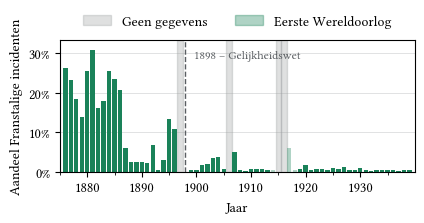

In [8]:

UITGESLOTEN = {'MA#41579'} # hulpbureel Linkeroever
PERIODE = (1876, 1939)
WOI = (1914, 1918)                  
NL_PROCENT = FuncFormatter(lambda x, pos: f'{x*100:,.0f}'.replace(',', '.') + '%')

fig, ax = plt.subplots(figsize=(TEKSTBREEDTE, TEKSTBREEDTE * 0.55))

is_woi = frans_per_jaar['year'].between(*WOI)
waarden = frans_per_jaar['french_proportion'].fillna(0)

ax.bar(frans_per_jaar.loc[~is_woi, 'year'], waarden[~is_woi],
       width=0.8, color=KLEUR_A, linewidth=0)

ax.bar(frans_per_jaar.loc[is_woi, 'year'], waarden[is_woi],
       width=0.8, color=KLEUR_A, alpha=0.35, linewidth=0)

# ── Jaren zonder gegevens lichtgrijs arceren ───────────────────────────
for j in frans_per_jaar.loc[frans_per_jaar['french_proportion'].isna(), 'year']:
    ax.axvspan(j - 0.5, j + 0.5, color='#96999B', alpha=0.30, zorder=0)

# ── Gelijkheidswet 1898 ────────────────────────────────────────────────
ax.axvline(x=1898, color=KLEUR_B, linestyle='--', linewidth=1.0, zorder=1)
ax.text(
    1899.5, frans_per_jaar['french_proportion'].max(),
    '1898 – Gelijkheidswet',
    color=KLEUR_B, ha='left', va='top', fontsize=CORPS_KLEIN
)

ax.set_xlabel('Jaar')
ax.set_ylabel('Aandeel Franstalige incidenten')
ax.yaxis.set_major_formatter(NL_PROCENT)

# ── Om de 10 jaar een label, om de 5 jaar een streepje ─────────────────
start = (int(frans_per_jaar['year'].min()) // 5) * 5
eind = int(frans_per_jaar['year'].max())
ax.set_xticks(range(((start + 9) // 10) * 10, eind + 1, 10))
ax.set_xticks(range(start, eind + 1, 5), minor=True)
ax.set_ylim(0, frans_per_jaar['french_proportion'].max() * 1.08)
ax.set_xlim(frans_per_jaar['year'].min() - 1, frans_per_jaar['year'].max() + 1)
ax.tick_params(axis='both', labelsize=CORPS)

ax.yaxis.grid(True)
ax.xaxis.grid(False)
ax.set_axisbelow(True)

ax.legend(
    handles=[
        Patch(color='#96999B', alpha=0.30, label='Geen gegevens'),
        Patch(color=KLEUR_A, alpha=0.35, label='Eerste Wereldoorlog'),
    ],
    loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2,
    fontsize=CORPS, frameon=False,
)

plt.tight_layout()

pas_breedte_aan(fig)
fig.savefig(FIGUREN / "3.7_frans_per_jaar.png", dpi=300)
plt.show()

In [9]:
n = len(incidenten)
print(f"n = {n:,}".replace(",", "."))

n = 160.027


In [10]:
n_frans = incidenten["frans"].sum()
print(f"{n_frans:,} Franstalige gebeurtenissen".replace(",", "."))
print(f"{n_frans / len(incidenten):.1%} van het totaal".replace(".", ","))

7.042 Franstalige gebeurtenissen
4,4% van het totaal
